# code_059 · Feature selection and stability

**Book:** section 12.3. A self-contained feature-engineering laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_12_GUIDE.md), [run evidence](../CHAPTER_12_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_059).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose representation assumptions, fitting boundaries and operational constraints without field-validity, causal or universal feature-selection claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1259;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1259


<a id="design"></a>
## Correlated channels can share predictive information

Generate 440 independent members. Two channels measure the same latent u with independent noise .08; a third measures independent v with noise .05; five channels are pure noise. Target displacement y=2u+.8v+Normal(0,.5) mm. Fix training/development/final roles 240/80/120. Neither channel is an identified cause. Correlation and predictive usefulness do not establish causal relevance.

Compare fixed filter SelectKBest(f_regression,k=2)+Ridge alpha=1; wrapper RFE(Ridge alpha=1,2 columns,step=1)+Ridge 1; and embedded Lasso alpha=.08,tol=1e-8,max_iter=10000. Each begins with training-only StandardScaler. Four shuffled folds inside the 240 training rows refit both scaling and selection; scores audit procedures rather than select controls. The final 120 rows are opened only after all procedures are fixed.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest,f_regression,RFE
from sklearn.linear_model import Ridge,Lasso
from sklearn.model_selection import KFold,cross_val_score
from sklearn.metrics import mean_squared_error
u=rng.normal(size=440);v=rng.normal(size=440);X=np.column_stack([u+rng.normal(0,.08,440),u+rng.normal(0,.08,440),v+rng.normal(0,.05,440),rng.normal(size=(440,5))]);y=2*u+.8*v+rng.normal(0,.5,440);tr=np.arange(240);dv=np.arange(240,320);te=np.arange(320,440)
assert X.shape==(440,8) and not set(tr)&set(te)
names=['u_A','u_B','v_C','noise_1','noise_2','noise_3','noise_4','noise_5']
procedures={'filter_two':make_pipeline(StandardScaler(),SelectKBest(f_regression,k=2),Ridge(alpha=1)),'RFE_two':make_pipeline(StandardScaler(),RFE(Ridge(alpha=1),n_features_to_select=2,step=1),Ridge(alpha=1)),'Lasso':make_pipeline(StandardScaler(),Lasso(alpha=.08,tol=1e-8,max_iter=10000))}
folds=list(KFold(4,shuffle=True,random_state=SEED).split(X[tr]));metrics={}
for name,pipe in procedures.items():
 scores=-cross_val_score(pipe,X[tr],y[tr],cv=folds,scoring='neg_mean_squared_error');pipe.fit(X[tr],y[tr]);selected=pipe[1].get_support() if name!='Lasso' else np.abs(pipe[-1].coef_)>1e-8
 metrics[name]={'CV_MSE_mm2':scores.tolist(),'development_MSE_mm2':float(mean_squared_error(y[dv],pipe.predict(X[dv]))),'final_MSE_mm2':float(mean_squared_error(y[te],pipe.predict(X[te]))),'selected_channels':[names[j] for j in np.flatnonzero(selected)]}
RESULTS['fixed_procedure_metrics']=metrics;RESULTS['training_proxy_correlation']=float(np.corrcoef(X[tr,:2],rowvar=False)[0,1])


<a id="resampling"></a>
## Report variation across resamples

Forty half-samples without replacement use only the 240 training rows. Refit standardization and each selector inside every sample. The Lasso support threshold is numerical 1e-8. Frequencies and pairwise Jaccard summaries describe this fixed resampling design, not population probabilities, posterior inclusion or formal stability-selection false-discovery guarantees. A predeclared Lasso-frequency threshold .7 constructs one additional stable-set candidate; no final score chooses it. If a set were empty the fallback would be the training mean, not a hidden feature choice.


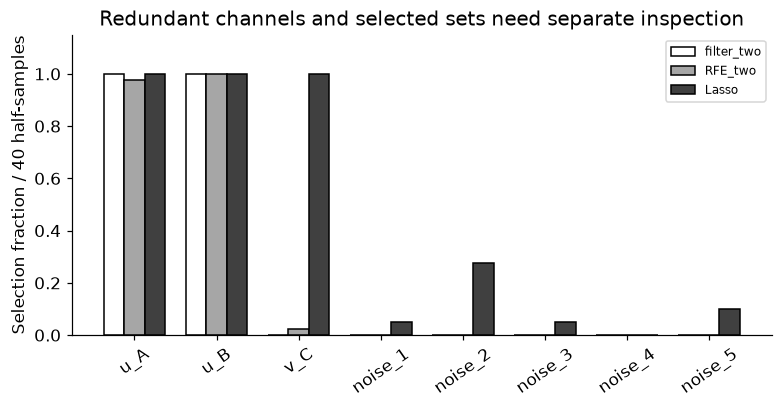

In [3]:
supports={name:[] for name in procedures}
for repeat in range(40):
 idx=rng.choice(tr,120,replace=False);S=StandardScaler().fit_transform(X[idx])
 supports['filter_two'].append(SelectKBest(f_regression,k=2).fit(S,y[idx]).get_support());supports['RFE_two'].append(RFE(Ridge(alpha=1),n_features_to_select=2,step=1).fit(S,y[idx]).support_);supports['Lasso'].append(np.abs(Lasso(alpha=.08,tol=1e-8,max_iter=10000).fit(S,y[idx]).coef_)>1e-8)
frequency={k:np.mean(v,axis=0) for k,v in supports.items()};jaccard={}
for name,sets in supports.items():
 vals=[]
 for i in range(len(sets)):
  for j in range(i):
   union=np.sum(sets[i]|sets[j]);vals.append(float(np.sum(sets[i]&sets[j])/union) if union else 1.)
 jaccard[name]=float(np.mean(vals))
stable=frequency['Lasso']>=.7
if stable.any():
 stablefit=make_pipeline(StandardScaler(),Ridge(alpha=1)).fit(X[tr][:,stable],y[tr]);p=stablefit.predict(X[te][:,stable])
else:p=np.full(len(te),y[tr].mean())
assert np.isfinite(p).all();assert all(np.logical_and(f>=0,f<=1).all() for f in frequency.values())
RESULTS['selection_frequencies']={k:v.tolist() for k,v in frequency.items()};RESULTS['mean_pairwise_Jaccard']=jaccard;RESULTS['stable_Lasso_channels']=[names[j] for j in np.flatnonzero(stable)];RESULTS['stable_set_final_MSE_mm2']=float(mean_squared_error(y[te],p));RESULTS['resampling_repeats']=40
fig,ax=plt.subplots(figsize=(7,3.6));k=np.arange(8)
for j,(name,freq) in enumerate(frequency.items()):ax.bar(k+(j-1)*.25,freq,.25,color=['white','.65','.25'][j],edgecolor='black',label=name)
ax.set(xticks=k,xticklabels=names,ylim=(0,1.15),ylabel='Selection fraction / 40 half-samples',title='Redundant channels and selected sets need separate inspection');ax.tick_params(axis='x',labelrotation=35);ax.legend(fontsize=8);plt.show()


<a id="diagram"></a>
## Nest selection inside each fit boundary

Training folds fit both preprocessing and the selector. Held-out folds receive only the stored selected columns and transform; their labels score the resulting predictor. Repeating selection on all rows before splitting would invalidate this comparison. The diagram pairs that boundary with the frequency plot, fulfilling the selected-set stability question without claiming that stability proves scientific truth.


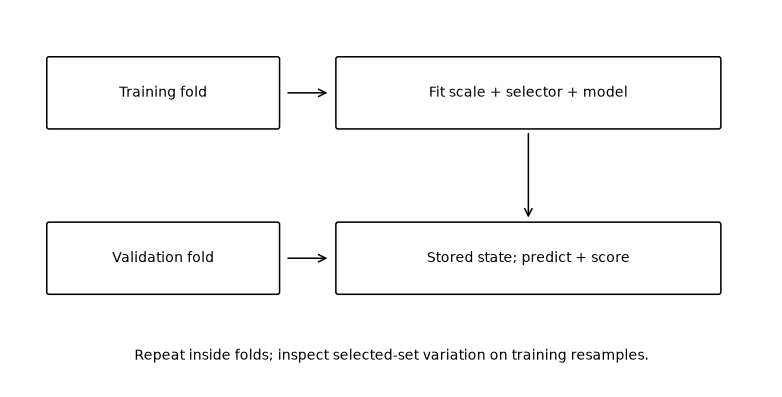

In [4]:
from matplotlib.patches import FancyBboxPatch,FancyArrowPatch
fig,ax=plt.subplots(figsize=(7,3.5));ax.axis('off');ax.set(xlim=(0,10),ylim=(0,5))
for cx,cy,label in [(2,3.9,'Training fold'),(6.8,3.9,'Fit scale + selector + model'),(2,1.7,'Validation fold'),(6.8,1.7,'Stored state; predict + score')]:
 w=3 if cx==2 else 5;ax.add_patch(FancyBboxPatch((cx-w/2,cy-.45),w,.9,boxstyle='round,pad=.03',fc='white'));ax.text(cx,cy,label,ha='center',va='center',fontsize=9)
for a,b in [((3.6,3.9),(4.2,3.9)),((3.6,1.7),(4.2,1.7)),((6.8,3.4),(6.8,2.2))]:ax.add_patch(FancyArrowPatch(a,b,arrowstyle='->',mutation_scale=12))
ax.text(5,.35,'Repeat inside folds; inspect selected-set variation on training resamples.',ha='center',fontsize=9);plt.show()


In [5]:
summary={'example_id':'code_059','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['filter wrapper and embedded selectors', 'selection inside validation pipelines', 'correlated proxies and resample variation', 'frequency diagnostics without error-control claims'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["filter wrapper and embedded selectors", "selection inside validation pipelines", "correlated proxies and resample variation", "frequency diagnostics without error-control claims"], "elapsed_seconds": 0.404, "example_id": "code_059", "hardware": "Darwin arm64 CPU", "results": {"fixed_procedure_metrics": {"Lasso": {"CV_MSE_mm2": [0.23069698297604932, 0.3483778314692379, 0.2652792413069464, 0.30068098120397274], "development_MSE_mm2": 0.3215390199032856, "final_MSE_mm2": 0.28253064345115475, "selected_channels": ["u_A", "u_B", "v_C"]}, "RFE_two": {"CV_MSE_mm2": [0.7028394144090669, 0.9105859681898373, 0.8940934629652694, 0.809372459922805], "development_MSE_mm2": 0.8034288006410609, "final_MSE_mm2": 1.0489439839979011, "selected_channels": ["u_A", "u_B"]}, "filter_two": {"CV_MSE_mm2": [0.7028394144090669, 0.9105859681898373, 0.8940934629652694, 0.809372459922805], "development_MSE_mm2": 0.8034288006410609, "final_MSE_mm2": 1.0489439839979